# Time Series Analysis
**Dataset:** Stock prices data
**Goal:** Plot the data, split it into trend, seasonality and residuals, and smooth it with a moving average.
**Tools:** Python, pandas, matplotlib, statsmodels

## Load the data
I load the stock prices file and look at the first rows.

In [ ]:
import os
import pandas as pd 
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

os.makedirs("plots",exist_ok=True)
df = pd.read_csv("../datasets/2) stock prices data set.csv")
df.head()


## Look at the data
I check the size, the column names and types, and if anything is missing.

In [ ]:
print("Rows and columns are:", df.shape)
df.info()

In [7]:
print(df.isnull().sum())
df.describe().round(2)

symbol     0
date       0
open      11
high       8
low        8
close      0
volume     0
dtype: int64


,open,high,low,close,volume
count,497461.00,497464.00,497464.00,497472.00,4.974720e+05
mean,86.35,87.13,85.55,86.37,4.253611e+06
std,101.47,102.31,100.57,101.47,8.232139e+06
min,1.62,1.69,1.50,1.59,0.000000e+00
25%,41.69,42.09,41.28,41.70,1.080166e+06
50%,64.97,65.56,64.35,64.98,2.084896e+06
75%,98.41,99.23,97.58,98.42,4.271928e+06
max,2044.00,2067.99,2035.11,2049.00,6.182376e+08


## Pick one company
The file holds many companies. A time series needs one value per date, so I choose one company.

In [8]:
print(df["symbol"].nunique(), "companies")

counts = df["symbol"].value_counts()
counts.head()

505 companies


symbol
AAL     1007
AAPL    1007
AAP     1007
ABBV    1007
ABC     1007
Name: count, dtype: int64

In [10]:
company = counts.index[4]   # the company with the most rows
# company = "ABC"          # or type a symbol you know, if it is in the list

stock = df[df["symbol"] == company].copy()
print("Company:", company)
print("Rows:", len(stock))

Company: ABC
Rows: 1007


In [11]:
company = "ABC"

stock = df[df["symbol"] == company].copy()

print("Company:", company)
print("Rows:", len(stock))

Company: ABC
Rows: 1007


In [12]:
print(df[df["symbol"].str.contains("ABC")]["symbol"].unique())

<StringArray>
['ABC']
Length: 1, dtype: str


In [13]:
stock["date"]= pd.to_datetime(stock["date"])
stock = stock.set_index("date")
stock = stock.sort_values("date")

print("From:", stock.index.min())
print("To", stock.index.max())
print("Missing close values:", stock["close"].isnull().sum())

From: 2014-01-02 00:00:00
To 2017-12-29 00:00:00
Missing close values: 0


ABC has daily prices from 2 January 2014 to 29 December 2017, about 4 years. There are no missing closing prices.

## Plot the time series
I plot ABC's closing price from 2014 to 2017 to look for patterns.

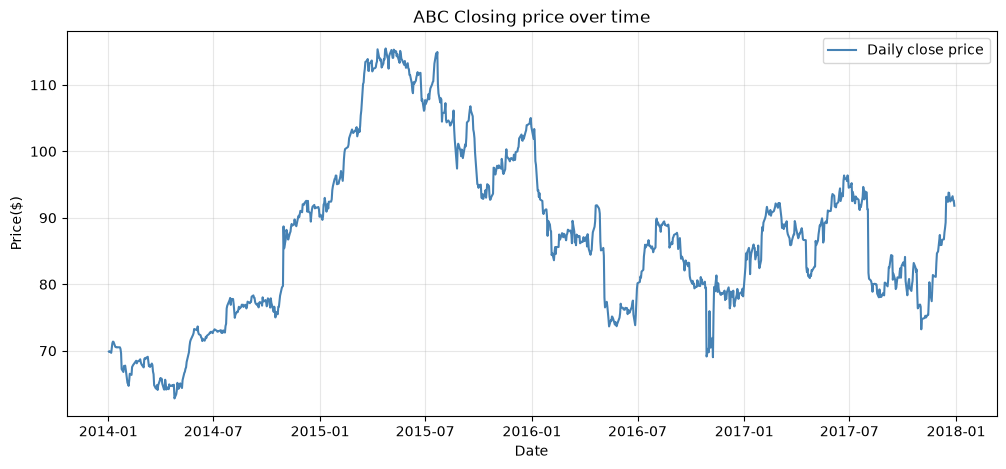

In [15]:
plt.figure(figsize=(12,5))
plt.plot(stock.index, stock["close"],color = "steelblue", label = "Daily close price")
plt.title(company + " Closing price over time")
plt.xlabel("Date")
plt.ylabel("Price($)")
plt.legend()
plt.grid(alpha = 0.3)

plt.savefig("plots/stock_price.png")
plt.show()

Between 2014 and 2017 the price moved up and down. I can see that between 2014-7 and 2015-7 the prices increased very highly and afterwards it dropped while increasing though at at a low rate so it kept the trend of up and down.

The price of ABC fluctuated between approximately $65 and $70 in 2014. However, the price rose steeply and peaked at approximately $115 in Spring 2015. Since then, the price has decreased steadily over the course of over a year, hitting its lowest point in mid-2016 with a price of approximately $75. Between late 2016 and end 2017, there is a fluctuation in prices between approximately $75 and $95. There are some notable decreases in price (such as in November 2016)

## Decompose the series
I split the series into trend (long-term direction), seasonality (a repeating yearly pattern) and residuals (what is left over). I use monthly averages so a yearly pattern has 12 steps.

In [16]:
monthly = stock["close"].resample("MS").mean()

print("Months:", len(monthly))
print("Missing months:", monthly.isnull().sum())

Months: 48
Missing months: 0


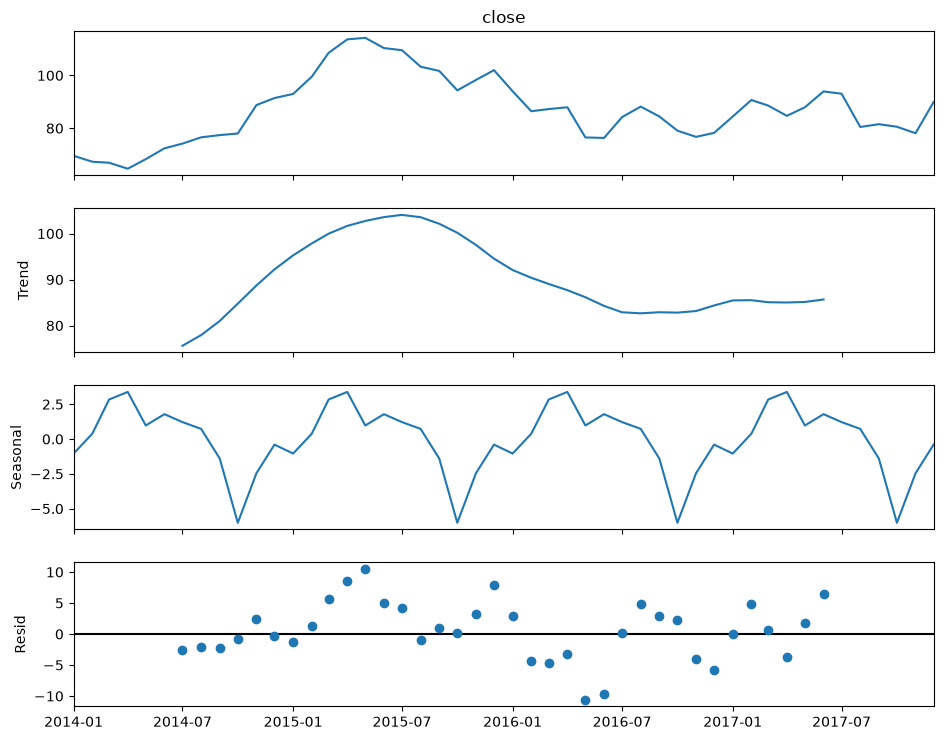

In [17]:
result = seasonal_decompose(monthly, model="additive", period=12)

fig = result.plot()
fig.set_size_inches(10, 8)

plt.savefig("plots/decomposition.png")
plt.show()

In [18]:
result.seasonal.head(12).round(2)

date
2014-01-01   -1.04
2014-02-01    0.38
2014-03-01    2.84
2014-04-01    3.38
2014-05-01    0.97
2014-06-01    1.79
2014-07-01    1.22
2014-08-01    0.73
2014-09-01   -1.40
2014-10-01   -6.01
2014-11-01   -2.45
2014-12-01   -0.40
Freq: MS, Name: seasonal, dtype: float64

## Monthly average price
Prices increase to reach approximately $114 in spring 2015 before decreasing. Prices fluctuated between approximately $77 and $94.
## Trend
Overall prices seem to follow this trend line. Prices increased from approximately $76 in mid-2014 to $104 in mid-2015. After this the price decreased to approximately $83 in mid-2016, and since then have remained fairly constant. There are no data points at the beginning and end of this graph due to needing data from previous and following months for calculation.
## Seasonality
There is seasonality in these data. In Spring (March/April) prices tend to be slightly higher than the trend value, approximately $3 higher. In October prices tend to be much lower than the trend value, approximately $6 lower. This seasonality is quite minor given that the price range is between $65 and $115. As there are only 4 years of data, this result should be treated with caution.
## Residuals
The residual values after removing the trend and seasonality can be seen here. The residuals are fairly close to 0. Most residuals are within approximately $5. Some values are outside of this, with as high as +$10 in Spring 2015, and as low as -$10 in Spring 2016. These correspond to periods in time where the price changed the fastest. Therefore, from this we can see that although the trend and seasonality account for most of the change in price, the largest changes do not occur due to these factors.

## Moving average smoothing
A moving average replaces each day's price with the average of the last few days. This removes the daily zigzag so the trend is easier to see.

In [19]:
stock["MA_30"] = stock["close"].rolling(window=30).mean()
stock["MA_100"] = stock["close"].rolling(window=100).mean()

stock[["close", "MA_30", "MA_100"]].tail()

,close,MA_30,MA_100
date,,,
2017-12-22,92.46,84.786333,81.3991
2017-12-26,93.25,85.394667,81.5145
2017-12-27,92.60,85.968000,81.6322
2017-12-28,92.59,86.541000,81.7523
2017-12-29,91.82,87.017333,81.8672


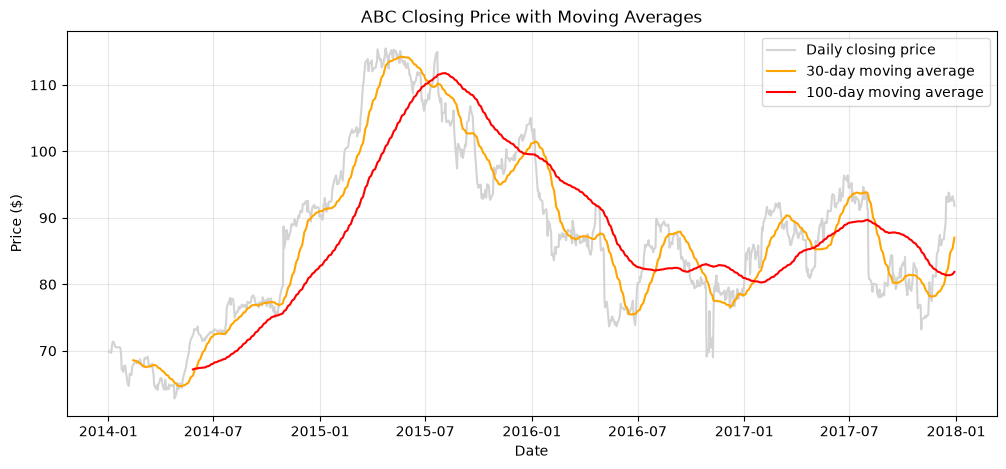

In [20]:
plt.figure(figsize=(12, 5))
plt.plot(stock.index, stock["close"], color="lightgray", label="Daily closing price")
plt.plot(stock.index, stock["MA_30"], color="orange", label="30-day moving average")
plt.plot(stock.index, stock["MA_100"], color="red", label="100-day moving average")
plt.title(company + " Closing Price with Moving Averages")
plt.xlabel("Date")
plt.ylabel("Price ($)")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig("plots/moving_averages.png")
plt.show()

## moving averages
The grey line shows the daily price, while the 30-day average (orange) is much more smoothed out. The 100-day average (red) has the longest smoothing. In general, the price follows an upwards trend until early 2015, falls until the middle of 2016 and then remains flat. The 100 day average line is therefore slower reacting. For example, while the daily price reached its maximum in Spring 2015, the 100 day average only reached its maximum a few months later. In periods of increasing prices, the 30 day average crosses above the 100 day average. In periods of decreasing prices, it crosses below.

## Summary
ABC stock data was selected out of the many companies in the data. Between 2nd Jan 2014 and 29th Dec 2017, there was no missing data. The overall trend was:
The price increased from approximately $70 in early 2014 to a high of approximately $115 in Spring 2015. It then decreased to approximately $75 in mid 2016. From this point, the price fluctuated between approximately $75 and $95 to the end of 2017.
## Trend
The trend increased until mid 2015, decreased until mid 2016, and was relatively flat after this.
## Seasonality
Seasonality shows repeating patterns. In spring, prices are slightly higher than the trend. In October prices are much lower than the trend. However, it is quite small relative to the size of the price meaning that seasonality has only a weak effect on this data.
## Residuals
Residuals are centred around zero. However, the size of residuals is larger (up to ~$10) in periods where the price changed rapidly, in 2015 and 2016.
## Moving Averages
The daily fluctuations were reduced. The 100 day moving average gave the smoothest line, and best shows the overall trend. However, it also reacts slower than the 30 day moving average.
## Conclusion
Overall, the price of ABC stock is largely influenced by trends, and less by seasonality.
Plots
All graphs have been saved as images in the Plots folder.